# Linear Regression

In [37]:
# get necessary dependancies
import pandas as pd
from mongo_wrangle import get_data
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error,root_mean_squared_error
from sklearn.linear_model import LinearRegression

In [38]:
host="localhost"
port = 27017

In [39]:
# get data
df =get_data(port,host,"passengers","air_passengers")
df["month"]=pd.to_datetime(df["month"])
df=df.set_index("month")


## Time series plot

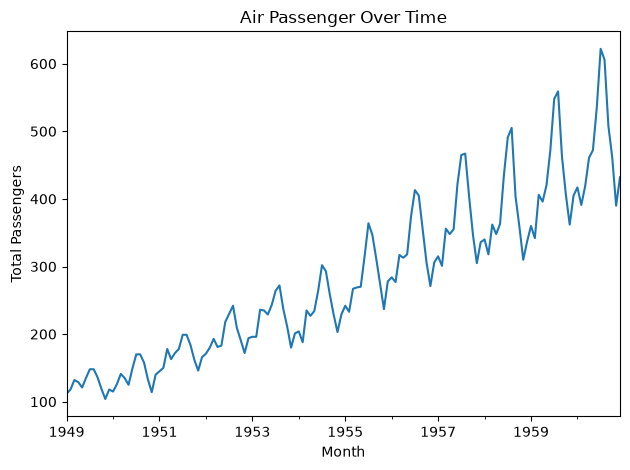

In [40]:
fig,ax =plt.subplots()
df.plot(ax=ax,y="total_passengers",legend=False)
ax.set_xlabel("Month")
ax.set_ylabel("Total Passengers")
ax.set_title("Air Passenger Over Time")
plt.tight_layout()
plt.show()

### Findings 
1. The plot is non stationary
2. The data has seasonality

In [41]:
# Make the time series stable
# log transform to stabilize variance
df["log_passengers"]=np.log(df["total_passengers"])


# differencing to remove trend and seasonality
df["log_diff"]=df["log_passengers"].diff()
df["log_diff_seasonal"]=df["log_diff"].diff(12)
df

,total_passengers,log_passengers,log_diff,log_diff_seasonal
month,,,,
1949-01-01,112,4.718499,NaN,NaN
1949-02-01,118,4.770685,0.052186,NaN
1949-03-01,132,4.882802,0.112117,NaN
1949-04-01,129,4.859812,-0.022990,NaN
1949-05-01,121,4.795791,-0.064022,NaN
...,...,...,...,...
1960-08-01,606,6.406880,-0.026060,-0.045934
1960-09-01,508,6.230481,-0.176399,0.012024
1960-10-01,461,6.133398,-0.097083,0.031830


In [42]:
# check for stationarity
def check_stationarity(series):
    result=adfuller(series.dropna())
    return result

In [43]:
check_stationarity(df["total_passengers"])[1]

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_5224/4049249682.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series.dropna())


0.991880243437641

In [44]:
check_stationarity(df["log_diff_seasonal"])[1]

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_5224/4049249682.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series.dropna())


0.0002485912311384052

### Create lag feature

In [45]:
df_original=df.copy()
df =(
    df.assign(
        lag_1=lambda x:x["log_diff_seasonal"].shift(1)
    )
    .dropna()
    
)

In [46]:
df

,total_passengers,log_passengers,log_diff,log_diff_seasonal,lag_1
month,,,,,
1950-03-01,141,4.948760,0.112478,0.000361,0.039164
1950-04-01,135,4.905275,-0.043485,-0.020496,0.000361
1950-05-01,125,4.828314,-0.076961,-0.012939,-0.020496
1950-06-01,149,5.003946,0.175633,0.066148,-0.012939
1950-07-01,170,5.135798,0.131852,0.039915,0.066148
...,...,...,...,...,...
1960-08-01,606,6.406880,-0.026060,-0.045934,0.001377
1960-09-01,508,6.230481,-0.176399,0.012024,-0.045934
1960-10-01,461,6.133398,-0.097083,0.031830,0.012024


### Separate features and target


In [47]:
y=df["log_diff_seasonal"]
x=df[["lag_1"]]

### Split data

In [48]:
split_idx=int(0.8 * len(df))
split_idx

X_train=x.iloc[:split_idx]
X_test=x.iloc[split_idx:]
y_train=y.iloc[:split_idx]
y_test=y.iloc[split_idx:]

### Baseline model

In [49]:
# prediction = previous observation
y_pred_log_baseline=X_test["lag_1"]
mean_absolute_error(y_test,y_pred_log_baseline)


0.054343020236920905

baseline model prediction are off by 5.43%

### Linear model

In [50]:
model =LinearRegression()
model.fit(X_train,y_train)
y_pred_train=model.predict(X_train)
y_pred_test=model.predict(X_test)




In [51]:
y_pred_train=pd.Series(y_pred_train,index=y_train.index)


### Inverse Differencing and Log Transformation.

In [52]:
#Training 
# undo seasonal differencing
seasonal_undiff=y_pred_train+df_original["log_diff"].shift(12).loc[y_train.index]
#undo first order differencing
previous_date =y_train.index[0]-pd.DateOffset(months=1)
previous_log_value=df_original.loc[previous_date,"log_passengers"]
log_pred=seasonal_undiff.cumsum()+previous_log_value

# undo log transform
passenger_pred=np.exp(log_pred)

passenger_pred




month
1950-03-01    139.091885
1950-04-01    135.861942
1950-05-01    128.248382
1950-06-01    143.641420
1950-07-01    154.025895
                 ...    
1958-06-01    434.078462
1958-07-01    476.859215
1958-08-01    474.951597
1958-09-01    407.515246
1958-10-01    359.000000
Length: 104, dtype: float64

In [53]:
len(y_test)

26

In [54]:
#Testing
# undo seasonal differencing
seasonal_undiff_test=y_pred_test+df_original["log_diff"].shift(12).loc[y_test.index]
#undo_first_order_differencing
previous_date_test =y_test.index[0]-pd.DateOffset(months=1)
previous_log_value_test=df_original.loc[previous_date_test,"log_passengers"]
log_pred_test=seasonal_undiff_test.cumsum()+previous_log_value_test

#undo log transform
pasenger_pred_test=np.exp(log_pred_test)
pasenger_pred_test


month
1958-11-01    311.919033
1958-12-01    345.498232
1959-01-01    351.006197
1959-02-01    322.371885
1959-03-01    364.957777
1959-04-01    345.903421
1959-05-01    358.957526
1959-06-01    427.642949
1959-07-01    492.805375
1959-08-01    501.984735
1959-09-01    402.521325
1959-10-01    353.488854
1959-11-01    306.210414
1959-12-01    329.530699
1960-01-01    348.575944
1960-02-01    335.050873
1960-03-01    399.310706
1960-04-01    402.653118
1960-05-01    410.312716
1960-06-01    466.309560
1960-07-01    539.661960
1960-08-01    550.032269
1960-09-01    462.325966
1960-10-01    404.647167
1960-11-01    356.022287
1960-12-01    404.768670
Name: log_diff, dtype: float64

In [55]:
original_y_train=df_original["total_passengers"].iloc[:split_idx]
original_y_test = df_original.loc[y_test.index, "total_passengers"]

In [56]:
train_mae=mean_absolute_error(original_y_train,passenger_pred)

train data linear regression model is off around 33 passengers

In [57]:
train_rmse=root_mean_squared_error(original_y_train,passenger_pred)

In [58]:
test=mae=mean_absolute_error(original_y_test,pasenger_pred_test)

In [59]:
test_rmse=root_mean_squared_error(original_y_test,pasenger_pred_test)

test data linear regression model is off by around 47 passengers

### scatterplot actual vs predicted

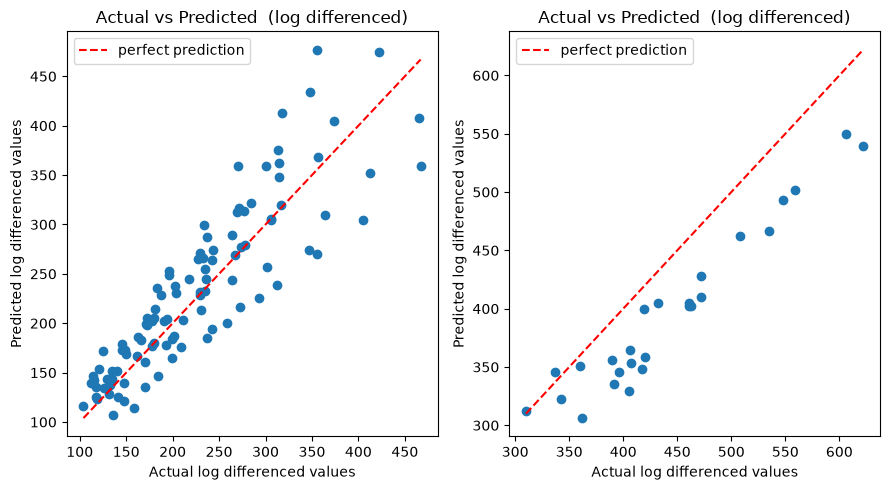

In [60]:
fig,axes =plt.subplots(1,2,figsize=(9,5))

axes[0].scatter(original_y_train,passenger_pred)
axes[0].plot([original_y_train.min(),original_y_train.max()],[original_y_train.min(),original_y_train.max()],"r--",label="perfect prediction")
axes[0].set_xlabel("Actual log differenced values")
axes[0].set_ylabel("Predicted log differenced values")
axes[0].set_title("Actual vs Predicted  (log differenced)")
axes[0].legend()




axes[1].scatter(original_y_test,pasenger_pred_test)
axes[1].plot([original_y_test.min(),original_y_test.max()],[original_y_test.min(),original_y_test.max()],"r--",label="perfect prediction")
axes[1].set_xlabel("Actual log differenced values")
axes[1].set_ylabel("Predicted log differenced values")
axes[1].set_title("Actual vs Predicted  (log differenced)")
axes[1].legend()
plt.tight_layout()
plt.show()




### Time series plot

In [61]:
test_result=pd.DataFrame({"Actual":original_y_test,"predicted":pasenger_pred_test},index=y_test.index)
test_result
# fig,ax=plt.subplots(figsize=(9,5))
# ax.plot()

,Actual,predicted
month,,
1958-11-01,310,311.919033
1958-12-01,337,345.498232
1959-01-01,360,351.006197
1959-02-01,342,322.371885
1959-03-01,406,364.957777
1959-04-01,396,345.903421
1959-05-01,420,358.957526
1959-06-01,472,427.642949
1959-07-01,548,492.805375


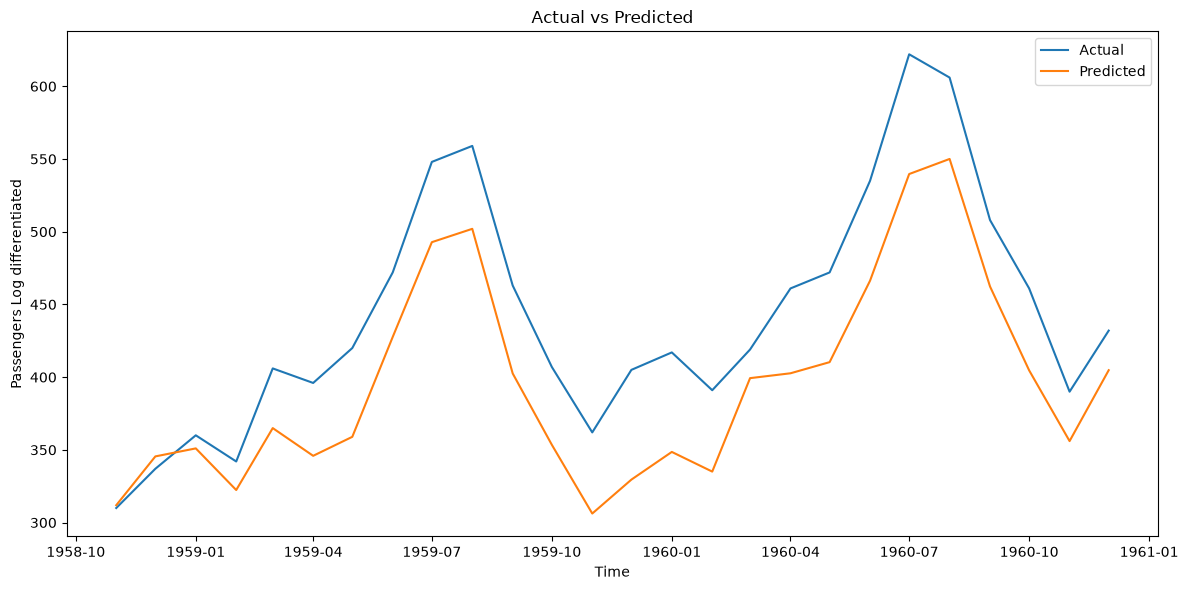

In [62]:
fig,ax=plt.subplots(figsize=(12,6))
ax.plot(test_result.index,test_result["Actual"],label="Actual")
ax.plot(test_result.index,test_result["predicted"],label="Predicted")
ax.set_xlabel("Time")
ax.set_ylabel("Passengers Log differentiated")
ax.set_title("Actual vs Predicted")
ax.legend()
plt.tight_layout()
plt.show()

In [63]:
%%writefile time_series_preprocessing.py

import numpy as np
import pandas as pd
# function to make data stationary
def make_data_stationary(df):
    # Make the time series stable
# log transform to stabilize variance
    df["log_passengers"]=np.log(df["total_passengers"])


    # differencing to remove trend and seasonality
    df["log_diff"]=df["log_passengers"].diff()
    df["log_diff_seasonal"]=df["log_diff"].diff(12)
    return  df

def reverse_stationary(pred,df):
   
    # undo seasonal differencing
    seasonal_undiff=pred+df["log_diff"].shift(12).loc[pred.index]
    #undo first order differencing
    previous_date =pred.index[0]-pd.DateOffset(months=1)
    previous_log_value=df.loc[previous_date,"log_passengers"]
    log_pred=seasonal_undiff.cumsum()+previous_log_value

    # undo log transform
    passenger_pred=np.exp(log_pred)

    return passenger_pred

Overwriting time_series_preprocessing.py
